# 02 — Modeling and evaluation

This notebook **reruns the existing Python analysis**, then compares the recomputed numerical results with the report snapshots supplied in this build. It does not substitute a display of cached metrics for model fitting.

We reproduce three distinct studies:

| Study | Outcome and evidence | Interpretation |
|---|---|---|
| National FSIS baseline/logistic comparison | Selected raw-poultry primary samples; lagged FSIS and calendar features | Retrospective feasibility |
| Earlier-source-snapshot stress test | Older FSIS source snapshots train a frozen estimator | Snapshot-consistent sensitivity, not verified release timing |
| Missouri integrated study | Seven-day selected-sample outcome, with lagged FSIS, BEAM, NOAA and optional NORS context | Conditional retrospective integration and added-data ablation |

**The target is selected FSIS sample positivity, not consumer illness or individual-lot safety.** CDC human surveillance never becomes an FSIS outcome label. Actual publication dates are unavailable; declared lags are assumptions. The integrated model remains closed to operational activation.

Run every code cell in order. Code and input snapshots are copied into a unique isolated workspace. The original inputs, published report snapshots and active operator database are preserved.


In [1]:
from pathlib import Path
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(
    candidate for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / "scripts/train_integrated_study.py").is_file()
    and (candidate / "backend").is_dir()
)
sys.path.insert(0, str(ROOT))
from scripts.notebook_support import NotebookRun

run = NotebookRun(ROOT, "02_modeling")
print("Isolated reproduction workspace:", run.workspace.relative_to(ROOT))


Isolated reproduction workspace: reports\notebook_runs\02_modeling-cf3e417c-630d-439a-b4e7-f50a2d1d0b53\project


## 1. Refit the national historical baseline and logistic comparison

The authoritative implementation is [scripts/train_model.py](../scripts/train_model.py). It applies the original result/cancellation filters, chronological split, 90-day label embargo, prevalence baseline, logistic fit, calibration and week-block bootstrap. No new feature definitions are introduced here.


In [2]:
run.run_script("scripts/train_model.py")
national = run.read_json("reports/model_evaluation.json")
national_expected = run.baseline_json("reports/model_evaluation.json")

assert national["target"] == national_expected["target"]
assert national["training_rows"] == national_expected["training_rows"]
assert national["validation_rows"] == national_expected["validation_rows"]
assert national["embargo_days"] == national_expected["embargo_days"]

metric_fields = ("brier", "pr_auc_average_precision", "roc_auc")
national_rows = []
for estimator in ("baseline", "logistic_regression"):
    actual = national[estimator]
    expected = national_expected[estimator]
    assert actual["n"] == expected["n"]
    assert actual["positives"] == expected["positives"]
    for metric in metric_fields:
        np.testing.assert_allclose(actual[metric], expected[metric], rtol=1e-8, atol=1e-10)
    np.testing.assert_allclose(
        actual["brier_week_block_bootstrap_95_ci"],
        expected["brier_week_block_bootstrap_95_ci"], rtol=1e-8, atol=1e-10,
    )
    national_rows.append({
        "estimator": estimator, "validation_n": actual["n"],
        "positives": actual["positives"],
        **{metric: actual[metric] for metric in metric_fields},
        "Brier_95_low": actual["brier_week_block_bootstrap_95_ci"][0],
        "Brier_95_high": actual["brier_week_block_bootstrap_95_ci"][1],
    })

display(pd.DataFrame(national_rows).set_index("estimator"))
display(pd.Series({
    "training_rows": national["training_rows"],
    "validation_rows": national["validation_rows"],
    "training_end": national["training_end"],
    "validation_start": national["validation_start"],
    "validation_end": national["validation_end"],
    "embargo_days": national["embargo_days"],
}, name="National chronological split").to_frame())
print(national["operational_selection"])


Baseline Brier: 0.08855575158082965 Logistic Brier: 0.08859439527274823 Validation n: 23472


,validation_n,positives,brier,pr_auc_average_precision,roc_auc,Brier_95_low,Brier_95_high
estimator,,,,,,,
baseline,23472,2303,0.088556,0.098117,0.500000,0.085435,0.092244
logistic_regression,23472,2303,0.088594,0.098141,0.498029,0.085476,0.092292


,National chronological split
training_rows,48361
validation_rows,23472
training_end,2025-05-30 00:00:00
validation_start,2025-08-29 00:00:00
validation_end,2026-06-30 00:00:00
embargo_days,90


smoothed historical prevalence; prospective skill not established


## 2. Recompute the earlier-source-snapshot sensitivity study

[scripts/validate_model_timing.py](../scripts/validate_model_timing.py) freezes training to source files with older metadata-creation dates. Training and validation source files are disjoint. A file-creation date does **not** establish the first public release or the availability of every result. This is another retrospective sensitivity analysis, not prospective validation.


In [3]:
run.run_script("scripts/validate_model_timing.py")
timing = run.read_json("reports/model_timing.json")
timing_expected = run.baseline_json("reports/model_timing.json")
assert timing["strict_split"] == timing_expected["strict_split"]
assert not set(timing["strict_split"]["training_files"]) & set(timing["strict_split"]["validation_files"])
assert timing["prospective_validation_feasible"] is False
assert timing["snapshot_release_verified"] is False

timing_rows = []
for estimator in ("snapshot_baseline", "calendar_logistic"):
    actual, expected = timing[estimator], timing_expected[estimator]
    for metric in metric_fields:
        np.testing.assert_allclose(actual[metric], expected[metric], rtol=1e-8, atol=1e-10)
    timing_rows.append({"estimator": estimator, "validation_n": actual["n"],
                        **{metric: actual[metric] for metric in metric_fields}})
display(pd.DataFrame(timing_rows).set_index("estimator"))
display(pd.Series(timing["strict_split"], name="Frozen-snapshot split").to_frame())
print(timing["feature_availability"])


Snapshot boundary 2026-03-19; train 57459, validation 7754; baseline Brier 0.09297314; calendar logistic Brier 0.09293427


,validation_n,brier,pr_auc_average_precision,roc_auc
estimator,,,,
snapshot_baseline,7754,0.092973,0.103559,0.500000
calendar_logistic,7754,0.092934,0.101889,0.499197


,Frozen-snapshot split
training_snapshot_cutoff,2026-03-19
training_rows,57459
validation_rows,7754
training_start,2023-10-01
training_end,2025-09-30
validation_start,2026-03-20
validation_end,2026-06-30
training_files,[usda_fsis_data_product_establishment_specific...
validation_files,[usda_fsis_data_product_establishment_specific...
snapshot_creation_dates,{'usda_fsis_data_product_establishment_specifi...


Training labels are frozen to earlier source snapshots and are not updated using held-out outcomes. Calendar month is known at the selected sample date. Metadata creation dates precede validation collection dates; first public release and row-level result availability are unverified. No availability dates were invented.


## 3. Refit the integrated Missouri study

[scripts/train_integrated_study.py](../scripts/train_integrated_study.py) calls [backend/integrated_study.py](../backend/integrated_study.py) to rebuild the analytic table, fit every model and ablation on the same complete-coverage cohort, calculate held-out metrics and uncertainty, and export monthly estimates with source gaps retained.

The comparison against the supplied report uses numerical tolerances, cohort identities and declared split dates. Generated timestamps and workspace-specific paths are not expected to match byte for byte.


In [4]:
run.run_script("scripts/train_integrated_study.py")
integrated = run.read_json("reports/integrated_model_evaluation.json")
integrated_expected = run.baseline_json("reports/integrated_model_evaluation.json")

assert integrated["target"] == integrated_expected["target"]
assert integrated["horizon_days"] == integrated_expected["horizon_days"]
assert integrated["primary_split"] == integrated_expected["primary_split"]
assert integrated["coverage"] == integrated_expected["coverage"]
assert integrated["availability_assumptions"] == integrated_expected["availability_assumptions"]
assert integrated["operational_activation_allowed"] is False
assert set(integrated["models"]) == set(integrated_expected["models"])

model_rows = []
for name, result in integrated["models"].items():
    actual = result["metrics"]
    expected = integrated_expected["models"][name]["metrics"]
    assert actual["n"] == integrated["primary_split"]["validation_rows"] == expected["n"]
    assert actual["positives"] == integrated["primary_split"]["validation_positives"] == expected["positives"]
    for metric in (*metric_fields, "precision_at_0_1", "recall_at_0_1",
                   "expected_calibration_error_fixed_bins"):
        np.testing.assert_allclose(actual[metric], expected[metric], rtol=1e-8, atol=1e-10)
    np.testing.assert_allclose(
        actual["brier_week_block_bootstrap_95_ci"],
        expected["brier_week_block_bootstrap_95_ci"], rtol=1e-8, atol=1e-10,
    )
    assert actual["confusion_at_0_1"] == expected["confusion_at_0_1"]
    for actual_bin, expected_bin in zip(actual["calibration"], expected["calibration"], strict=True):
        assert actual_bin["n"] == expected_bin["n"]
        for field in ("mean_predicted", "observed", "wilson_95_ci"):
            np.testing.assert_allclose(actual_bin[field], expected_bin[field], rtol=1e-8, atol=1e-10)
    model_rows.append({
        "model": name, "held_out_n": actual["n"], "positives": actual["positives"],
        **{metric: actual[metric] for metric in metric_fields},
        "Brier_95_low": actual["brier_week_block_bootstrap_95_ci"][0],
        "Brier_95_high": actual["brier_week_block_bootstrap_95_ci"][1],
        "precision_at_0.10": actual["precision_at_0_1"],
        "recall_at_0.10": actual["recall_at_0_1"],
    })

model_table = pd.DataFrame(model_rows).set_index("model")
display(model_table)
display(pd.Series(integrated["primary_split"], name="Primary split").to_frame())
display(pd.DataFrame(integrated["availability_assumptions"]).T)
print("Coverage exclusions:", integrated["coverage"]["excluded_incomplete_coverage"])
print("Operational activation allowed:", integrated["operational_activation_allowed"])


{
  "coverage": {
    "input_fsis_rows": 78607,
    "valid_fsis_samples": 78553,
    "national_states": 46,
    "mo_samples": 1534,
    "mo_establishments": 16,
    "mo_positives": 136,
    "eligible_samples": 490,
    "excluded_incomplete_coverage": 1044,
    "weather_station_count": 5,
    "weather_station_days": 2730,
    "weather_observation_start": "2025-01-01",
    "weather_observation_end": "2026-06-30",
    "beam_source_rows": 262616,
    "beam_mo_human_salmonella_rows": 3403,
    "nors_source_rows": 66713,
    "nors_mo_food_salmonella_records": 30,
    "geography_gate": "MO only; no national weather extrapolation",
    "availability_gate": "Conditional retrospective pass only; prospective publication availability unverified"
  },
  "primary_split": {
    "training_rows": 255,
    "training_positives": 20,
    "validation_rows": 171,
    "validation_positives": 22,
    "training_origin_start": "2025-02-10",
    "training_origin_end": "2025-09-25",
    "training_end": "2025-10-0

,held_out_n,positives,brier,pr_auc_average_precision,roc_auc,Brier_95_low,Brier_95_high,precision_at_0.10,recall_at_0.10
model,,,,,,,,,
baseline,171,22,0.114307,0.128655,0.500000,0.074757,0.155548,0.000000,0.000000
fsis,171,22,0.112557,0.172220,0.606772,0.073224,0.152966,0.180328,0.500000
fsis_cdc,171,22,0.112651,0.166354,0.599451,0.072954,0.153525,0.166667,0.545455
core_integrated,171,22,0.112456,0.152931,0.585265,0.072589,0.152442,0.173333,0.590909
with_nors,171,22,0.124489,0.167607,0.573978,0.078297,0.172439,0.000000,0.000000


,Primary split
training_rows,255
training_positives,20
validation_rows,171
validation_positives,22
training_origin_start,2025-02-10
training_origin_end,2025-09-25
training_end,2025-10-02
validation_start,2026-01-05
validation_end,2026-06-23
last_training_label_available_assumed,2025-12-31


,assumed_lag_days,basis,actual_publication_timestamps_present,source_observation_end
fsis,90,collection_date + lag,False,NaN
beam,90,month-end + lag,False,NaN
noaa,7,daily reporting-period end + lag; 28 trailing ...,False,NaN
nors,730,month-end + lag; latest available trailing12 e...,False,2023-12-31


Coverage exclusions: 1044
Operational activation allowed: False


## 4. Inspect uncertainty, calibration and added-data value

Lower Brier is better. The Brier intervals resample held-out calendar weeks; they do not quantify publication-lag uncertainty or transportability. Calibration Wilson bands use independent-binomial assumptions and omit clustering.

Added-data claims use **paired** changes on the same held-out cohort. An interval crossing zero does not establish improvement. A positive Brier change means worse error in this conditional holdout.


In [5]:
ablation_rows = []
for actual, expected in zip(integrated["ablations"], integrated_expected["ablations"], strict=True):
    assert actual["added_domain"] == expected["added_domain"]
    np.testing.assert_allclose(actual["brier_change"], expected["brier_change"], rtol=1e-8, atol=1e-10)
    np.testing.assert_allclose(
        actual["paired_week_block_bootstrap_95_ci"],
        expected["paired_week_block_bootstrap_95_ci"], rtol=1e-8, atol=1e-10,
    )
    lower, upper = actual["paired_week_block_bootstrap_95_ci"]
    ablation_rows.append({
        "added_domain": actual["added_domain"],
        "comparison": actual["reference_model"] + " → " + actual["augmented_model"],
        "Brier_change": actual["brier_change"],
        "paired_95_low": lower, "paired_95_high": upper,
        "interpretation": actual["interpretation"],
    })
display(pd.DataFrame(ablation_rows))


,added_domain,comparison,Brier_change,paired_95_low,paired_95_high,interpretation
0,PulseNet-derived BEAM aggregate,fsis → fsis_cdc,0.000095,-0.000971,0.001587,Paired interval includes zero; added value not...
1,NOAA ambient context,fsis_cdc → core_integrated,-0.000195,-0.001311,0.000644,Paired interval includes zero; added value not...
2,NORS exported outbreak-record context,core_integrated → with_nors,0.012033,0.005491,0.018963,Higher Brier in this conditional holdout; adde...
3,All integrated domains,baseline → with_nors,0.010183,0.003787,0.016888,Higher Brier in this conditional holdout; adde...


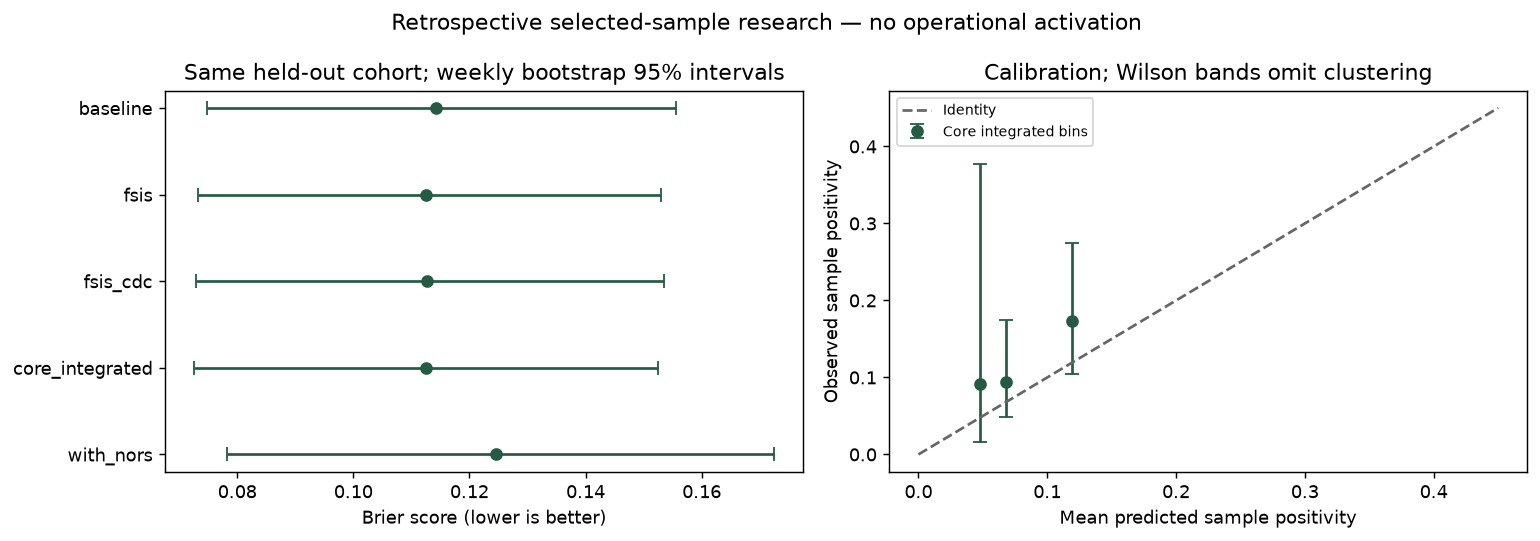

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
positions = np.arange(len(model_table))
brier = model_table["brier"].to_numpy()
axes[0].errorbar(
    brier, positions,
    xerr=np.vstack([brier - model_table["Brier_95_low"].to_numpy(),
                    model_table["Brier_95_high"].to_numpy() - brier]),
    fmt="o", capsize=4, color="#245b42",
)
axes[0].set_yticks(positions, model_table.index)
axes[0].invert_yaxis()
axes[0].set_xlabel("Brier score (lower is better)")
axes[0].set_title("Same held-out cohort; weekly bootstrap 95% intervals")

calibration = pd.DataFrame(integrated["models"]["core_integrated"]["metrics"]["calibration"])
observed = calibration["observed"].to_numpy()
axes[1].errorbar(
    calibration["mean_predicted"], observed,
    yerr=np.vstack([
        observed - calibration["wilson_95_ci"].map(lambda interval: interval[0]).to_numpy(),
        calibration["wilson_95_ci"].map(lambda interval: interval[1]).to_numpy() - observed,
    ]),
    fmt="o", capsize=4, color="#245b42", label="Core integrated bins",
)
axes[1].plot([0, 0.45], [0, 0.45], "--", color="#666666", label="Identity")
axes[1].set(xlabel="Mean predicted sample positivity", ylabel="Observed sample positivity",
            title="Calibration; Wilson bands omit clustering")
axes[1].legend(fontsize=8)
fig.suptitle("Retrospective selected-sample research — no operational activation", fontsize=12)
fig.tight_layout()
figure_path = run.workspace / "reports/notebook_model_evaluation.png"
fig.savefig(figure_path, dpi=130, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(figure_path)))


## 5. Retain the monthly source-coverage gap

A month with no eligible held-out samples has a sample count of zero and **no predicted or observed proportion**. It must not be rendered as an estimated zero risk.


In [7]:
monthly = pd.read_csv(run.workspace / "reports/integrated_model_timeseries.csv")
prediction_columns = [column for column in monthly if column.endswith("_mean")]
no_estimate = monthly["n"].eq(0)
assert monthly.loc[no_estimate, prediction_columns].isna().all().all()
assert monthly.loc[no_estimate, "positive_fraction"].isna().all()
display(monthly)
print("Report status:", integrated["status"])
display(pd.Series(integrated["limitations"], name="Scientific limitations").to_frame())


,month,n,positives,positive_fraction,baseline_mean,fsis_mean,fsis_cdc_mean,core_integrated_mean,with_nors_mean,coverage_reason
0,2026-01,45,3,0.066667,0.081712,0.064208,0.063740,0.054399,0.007947,Held-out selected samples with complete source...
1,2026-02,0,0,NaN,NaN,NaN,NaN,NaN,NaN,No held-out sample meets complete source-cover...
2,2026-03,22,3,0.136364,0.081712,0.085354,0.079732,0.081783,0.006577,Held-out selected samples with complete source...
3,2026-04,30,4,0.133333,0.081712,0.103435,0.113167,0.126029,0.019724,Held-out selected samples with complete source...
4,2026-05,42,8,0.190476,0.081712,0.106382,0.117470,0.115677,0.023014,Held-out selected samples with complete source...
5,2026-06,32,4,0.125000,0.081712,0.092364,0.068084,0.073053,0.018975,Held-out selected samples with complete source...


Report status: conditional retrospective multi-source feasibility; prospective skill unestablished


,Scientific limitations
0,This is a conditional retrospective feasibilit...
1,Target is positivity in selected FSIS raw-poul...
2,BEAM human Salmonella counts are PulseNet-deri...
3,NOAA is an equal-weight five-airport Missouri ...
4,NORS counts exported Missouri foodborne Salmon...
5,All models and ablations use the identical com...
6,"Regularization, feature sets, January 2026 pri..."
7,Week-block bootstrap intervals describe sampli...
8,Calibration and time-series Wilson intervals a...
9,Diagnostic false positives mean negative selec...


## 6. Preservation check and output record

The recomputed metrics above matched the supplied report snapshots within the declared tolerances. The cell below independently verifies that the original inputs, published results and operator-state bytes remain unchanged.

Recomputed JSON, CSV, figures and script logs are in this notebook's isolated workspace, printed at the start. They are review artifacts; they do not replace the application's published reports or enable the model for dispatch.


In [8]:
display(run.verify_preservation())
execution_manifest = run.finish()
print("Isolated execution record saved; application reports remain unchanged.")


{'passed': True,
 'changed_inputs': [],
 'operator_preserved': True,
 'raw_preserved': True,
 'changed_raw_inputs': []}

Isolated execution record saved; application reports remain unchanged.
